# 04 · Temperature and season — contribution 2

Wood-boring larvae are ectotherms: feeding activity rises steeply with trunk
temperature. So the acoustic evidence of infestation is **not constant** — an
infested tree sounds quiet in winter and busy in summer.

Single-recording classifiers never see this, because they never observe the
same tree twice. A detector that monitors one tree for months walks straight
into it: as spring arrives, a perfectly healthy tree warms up, its background
activity rises, and a temperature-blind detector reports an infestation.

The 2026 systematic review states the gap directly — **no system it appraised
demonstrated prospectively validated environmental adaptation of thresholds**
(gap RG-6).

TreeVibes encodes temperature in every filename, so the correction is free.

This notebook:
1. builds monitoring streams from **real timestamps**, not simulated ordering
2. shows that acoustic activity tracks temperature
3. shows a temperature-blind detector drifting on **healthy** trees
4. fixes it with a temperature-conditioned baseline

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # the nakheel-guard folder
for sub in ("src", "scripts"):
    sys.path.insert(0, str(ROOT / sub))

# These imports are wrapped because the most common way they fail on Anaconda
# produces an error that never mentions the real cause. Installing an audio
# library with pip can upgrade NumPy past 2.0, and Anaconda's pre-compiled
# matplotlib / scipy / pandas were built against NumPy 1.x -- so the failure
# surfaces as "initialization failed" deep inside matplotlib's import chain,
# with no hint that NumPy is responsible.
try:
    import numpy as np, pandas as pd, matplotlib.pyplot as plt
except ImportError as _exc:
    _numpy_version = "unknown"
    try:
        import numpy as _np_probe
        _numpy_version = _np_probe.__version__
    except Exception:
        pass
    raise ImportError(f"""Core imports failed. NumPy version: {_numpy_version}

This is almost always a mixed environment: some packages were built for
NumPy 1.x and others require NumPy 2.x, so no single NumPy version satisfies
everything. Typical symptoms are "module compiled using NumPy 1.x cannot be
run in NumPy 2" or "module 'numpy' has no attribute 'long'".

Pinning NumPy does NOT fix this -- in a genuinely mixed environment each pin
only moves the failure to a different package. Build a clean environment:

    conda create -n nakheel python=3.11 -y
    conda activate nakheel
    pip install -r requirements.txt
    pip install jupyterlab ipykernel
    python -m ipykernel install --user --name nakheel --display-name "Python (nakheel)"

then start Jupyter from that prompt and choose
Kernel -> Change Kernel -> Python (nakheel).

If a package is merely missing rather than mismatched, install it into THIS
kernel with:

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed <package>

Original error: {_exc}
""") from _exc

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

In [2]:
# ---------------------------------------------------------------- packages
# Check the packages this project needs are importable *in the Python that is
# running this notebook*. On Anaconda, `pip` on the command line often points
# at a different environment than Jupyter uses, which is a common and
# confusing source of "but I installed it" failures.
_missing = []
for _mod, _pkg in [("numpy", "numpy"), ("pandas", "pandas"),
                   ("sklearn", "scikit-learn"), ("scipy", "scipy"),
                   ("librosa", "librosa"), ("soundfile", "soundfile"),
                   ("joblib", "joblib"), ("matplotlib", "matplotlib"),
                   ("openpyxl", "openpyxl")]:
    try:
        __import__(_mod)
    except ImportError:
        _missing.append(_pkg)

if _missing:
    raise ImportError(f"""Missing packages: {', '.join(_missing)}

Install them into THIS kernel by running the following in a new cell,
then restart the kernel (Kernel -> Restart):

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed {' '.join(_missing)}

The --upgrade-strategy flag matters: without it pip may upgrade NumPy to
satisfy the new package, which can break other packages compiled against a
different NumPy generation. If that happens, see the README -- the fix is a
clean environment, not a NumPy pin.
""")

print("packages: OK")

# ---------------------------------------------------------------- dataset
# "mock"      - structurally faithful stand-in, synthetic audio. For testing.
# "treevibes" - the real download. Put it in data/treevibes/.
WHICH = "treevibes"

DATASETS = {
    "mock":      ROOT / "data" / "mock_treevibes",
    "treevibes": ROOT / "data" / "treevibes",
}
DATASET = DATASETS[WHICH]
TAG = "mock" if WHICH == "mock" else "treevibes"

# The Kaggle distribution splits into field/ and lab/. Only the field
# recordings describe deployed sensors on real trees -- the lab set is
# controlled-condition material that would both swamp the field data (roughly
# 53,000 clips against 4,000) and mix two very different acoustic regimes
# under one label. The published analyses use the field recordings, so that
# is what this project evaluates on.
if WHICH == "treevibes" and (DATASET / "field").is_dir():
    DATASET = DATASET / "field"
    print("using the field recordings only (lab/ excluded)")

if not DATASET.exists():
    if WHICH == "mock":
        # Imported and called directly rather than run as a subprocess, so a
        # failure arrives as an ordinary traceback naming its cause instead
        # of an opaque "non-zero exit status 1".
        import make_mock_treevibes
        print("building the mock dataset (a few minutes)...")
        make_mock_treevibes.generate(out=DATASET, folders=10, days=110,
                                     per_day=2, seconds=3.0)
    else:
        raise FileNotFoundError(f"""{DATASET} not found.

Download TreeVibes from
    https://www.kaggle.com/datasets/potamitis/treevibes
and extract it into
    {DATASET}
""")
print(f"dataset: {DATASET}  (tag '{TAG}')")

packages: OK
using the field recordings only (lab/ excluded)
dataset: C:\Users\DELL\Downloads\nakheel-final\nakheel-final\data\treevibes\field  (tag 'treevibes')


## 1. Reload the manifest, with time and temperature

In [3]:
import treevibes as TV, extract as E

manifest = pd.read_csv(ROOT / "results" / f"manifest_{TAG}.csv",
                       parse_dates=["timestamp"])
cached = E.load_cache(TAG)
if cached is None:
    raise FileNotFoundError(f"No cached features for '{TAG}'. Run notebook 01.")
X, y, groups, clip_ids, names = cached

if manifest["timestamp"].isna().all():
    raise ValueError("No timestamps in this dataset — notebook 04 needs them.")

print(TV.describe(manifest))

  recordings        : 2400
  class balance     : clean=1200, infested=1200
  recording groups  : 38
  groups with both classes : 0
  time span         : 2020-02-17 to 2020-07-08  (142 days)
  days per tree     : median 0, max 95
  temperature       : 0.8 to 48.6 C (median 9.7)

  NOTE: no tree is recorded in both states, so the
  within-tree contrast is unavailable. The per-tree
  method falls back to a pooled estimate; say so.


## 2. Score every recording, in real time order

In [4]:
from sequential import fit_shift_direction, fit_shift_direction_pooled
from temporal import score_recordings, daily_aggregate, seasonal_streams

trees = np.unique(groups)
rng = np.random.default_rng(0)
tree_label = {t: int(y[groups == t][0]) for t in trees}

try:
    w, scaler, _ = fit_shift_direction(X, y, groups)
except ValueError:
    w, scaler, _ = fit_shift_direction_pooled(X, y, groups)

scored = score_recordings(manifest, X, clip_ids, w, scaler)
daily = daily_aggregate(scored)
streams = seasonal_streams(daily, min_days=30)
print(f"{len(scored)} recordings -> {len(daily)} tree-days "
      f"-> {len(streams)} trees with >=30 days")

2054 recordings -> 71 tree-days -> 0 trees with >=30 days


## 3. Does activity track temperature?

If these curves slope upward, the confound is real in this data.

fitted temperature baselines for 0 trees


C:\Users\DELL\Downloads\nakheel-final\nakheel-final\src\plots.py:327: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, fontsize=8.5, ncol=2)


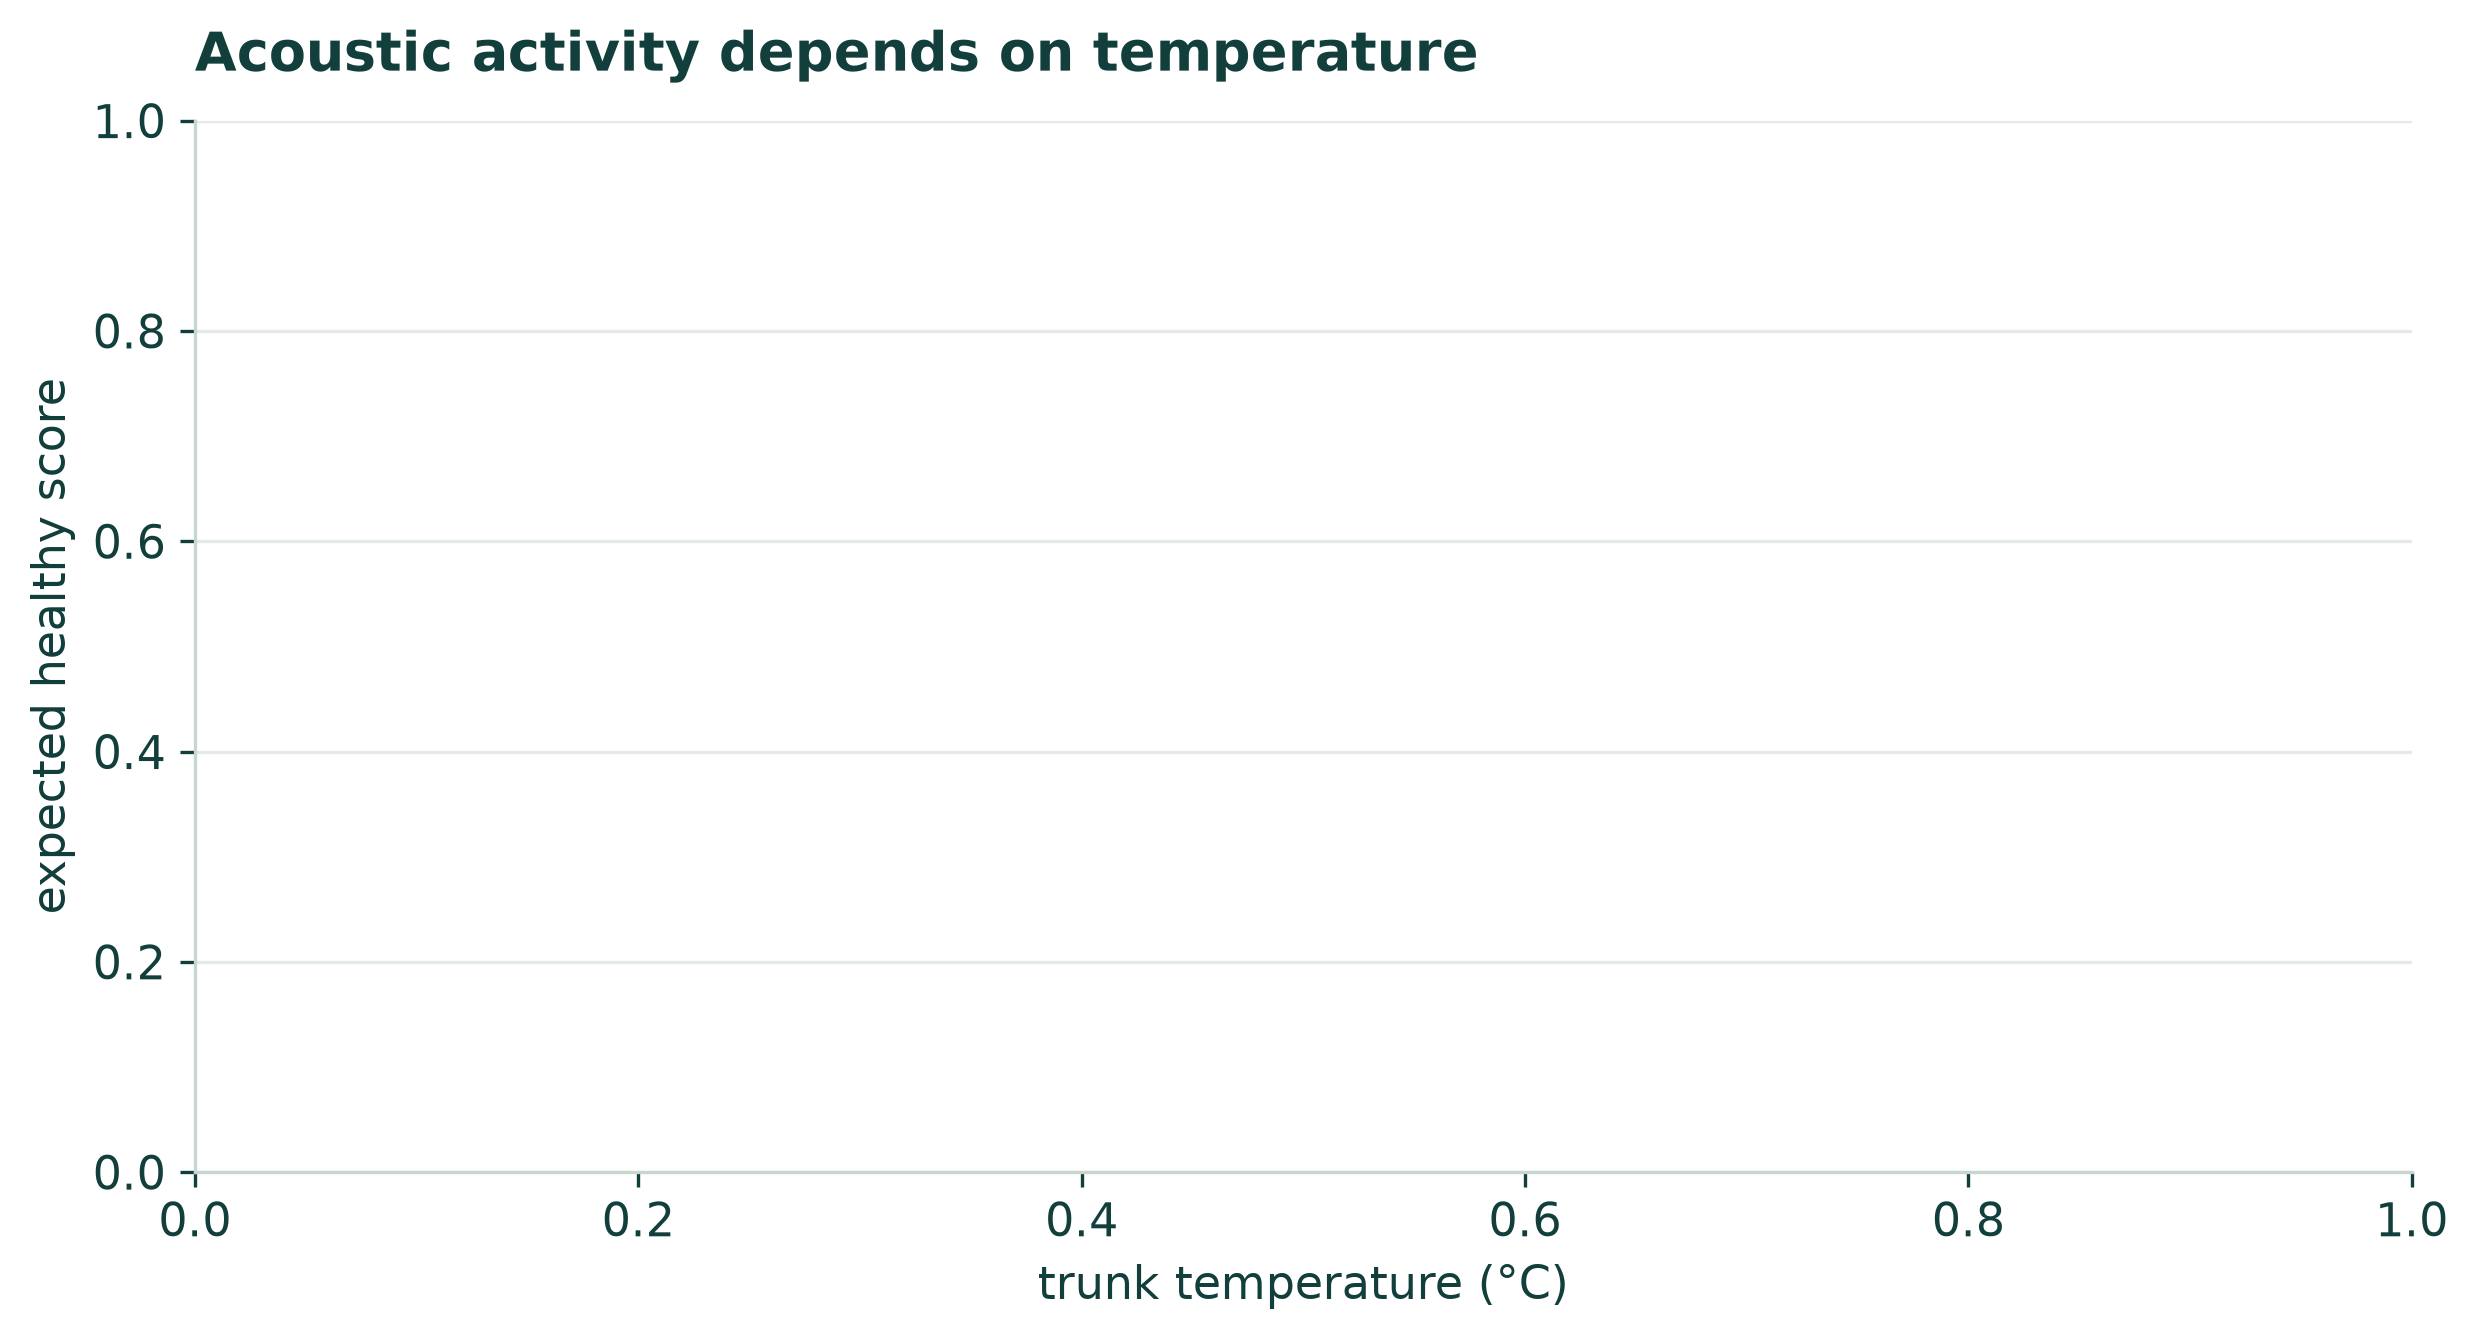

In [5]:
from temporal import TemperatureBaseline, split_learning_period
import plots as P
from IPython.display import Image, display

baselines, fits = {}, {}
for g, st in streams.items():
    fit, monitor = split_learning_period(st, fraction=0.4)
    if fit is None:
        continue
    try:
        bl = TemperatureBaseline.fit(fit["score"].values, fit["temperature_c"].values)
    except ValueError:
        continue
    baselines[g] = bl
    fits[g] = (fit, monitor)

print(f"fitted temperature baselines for {len(baselines)} trees")
display(Image(str(P.fig_temperature_response(baselines)), width=800))

In [6]:
# Correlation between score and temperature, per tree
rows = []
for g, st in streams.items():
    if st["temperature_c"].notna().sum() > 10:
        rows.append({"tree": g,
                     "label": "infested" if tree_label.get(g, 0) else "clean",
                     "corr": float(st["score"].corr(st["temperature_c"])),
                     "n_days": len(st)})
corr = pd.DataFrame(rows).sort_values("corr", ascending=False)
print(f"median correlation with temperature: {corr['corr'].median():+.3f}")
corr.round(3)

KeyError: 'corr'

## 4. The confound: a temperature-blind detector drifts on healthy trees

For every tree, fit both baselines on the learning period, then compare the
mean residual over the monitoring period. **On a healthy tree the residual
should stay near zero.** Upward drift in the blind version, but not the aware
version, is seasonal warming being misread as infestation.

In [7]:
from temporal import temperature_confound_test

labels = {g: ("infested" if tree_label.get(g, 0) else "clean") for g in streams}
conf = temperature_confound_test(streams, labels, fraction=0.4)
conf.round(3)

""


In [8]:
healthy = conf[conf.label == "clean"]
if len(healthy):
    print("Healthy trees — mean residual during monitoring (0 is correct)")
    print(f"  temperature-blind : {healthy['naive_residual_mean'].mean():+.3f}")
    print(f"  temperature-aware : {healthy['aware_residual_mean'].mean():+.3f}")
    print(f"  mean warming      : {healthy['temp_shift'].mean():+.1f} °C")
    improvement = (abs(healthy['naive_residual_mean'].mean())
                   - abs(healthy['aware_residual_mean'].mean()))
    print(f"\n  drift reduced by  : {improvement:+.3f} "
          f"standard deviations of false evidence per observation")
display(Image(str(P.fig_confound(conf)), width=880))

AttributeError: 'DataFrame' object has no attribute 'label'

### Why this matters operationally

Every unit of upward drift on a healthy tree is false evidence accumulating in
the CUSUM statistic from notebook 03. A sequential detector integrates
evidence over time — which is its strength — so it also integrates this bias.
Left uncorrected, a temperature-blind sequential detector raises a false alarm
on every healthy tree, every spring.

Correcting the baseline for temperature removes the drift without weakening
the detector, because it subtracts only the part of the signal that
temperature explains.

## 5. One real tree, start to finish

In [9]:
if baselines:
    g = max(baselines, key=lambda k: len(streams[k]))
    fit, monitor = fits[g]
    out = P.fig_real_timeline(
        streams[g], baselines[g], fit["date"].iloc[-1],
        f"{g} ({labels.get(g, '?')})")
    display(Image(str(out), width=860))

## 6. Save

In [10]:
conf.to_csv(P.RESULTS_DIR / "temperature_confound.csv", index=False)
corr.to_csv(P.RESULTS_DIR / "temperature_correlation.csv", index=False)
print("saved results/temperature_confound.csv")

NameError: name 'corr' is not defined

## What to claim, and what not to

**Claim:**
- Published evaluation protocols on this data leak across trees; notebook 02
  measures the gap.
- The infestation *direction* in feature space transfers across trees even
  though absolute features do not.
- Accumulating evidence detects a given infestation earlier than
  per-recording classification **at a matched false-alarm rate**.
- Acoustic activity in this dataset depends on temperature, and a
  temperature-blind monitoring detector drifts on healthy trees as the season
  warms. Conditioning each tree's baseline on temperature removes that drift.
- Because detection is relative to each tree's own baseline, the sensor does
  not need high absolute sensitivity. That is the engineering argument for
  low-cost hardware.

**Do not claim:**
- Any field validation. Nothing here has touched a living palm.
- Red Palm Weevil specificity. This is *Xylotrechus chinensis* in mulberry —
  a cross-species proxy, as the 2026 review states.
- That this solves early detection. It shifts the operating point; the
  underlying signal is still weak.
- Real-world false-alarm rates. The budget is calibrated on healthy streams
  built from this same data, not on a season of independent field recordings.

The review's harshest finding about this field is that 20 of the studies it
appraised lacked explicit limitations. Stating yours costs nothing and is what
separates a serious submission from a confident one.